# Clustering V2

For this experiment, I wanted to see how changing the number of clusters would affect the results. I tested k values from 1 to 10 using the same sentiment samples as V1.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task
from src.models.clustering import KMeans


I started by selecting the same 1000 sentiment samples as before.

In [2]:
X_train, y_train, _, _ = load_task("sentiment")
assert X_train.shape == (12000, 768)
rng = np.random.default_rng(42)
indices = rng.choice(len(X_train), size=1000, replace=False)
X_subset = X_train[indices]
y_subset = y_train[indices]
assert len(np.unique(indices)) == 1000
result_dir = project_root / "results" / "clustering"
v1_assignments = pd.read_csv(result_dir / "clustering_v1_assignments.csv")
assert indices.tolist() == v1_assignments["original_row_index"].tolist()
assert y_subset.tolist() == v1_assignments["true_label"].tolist()
print("The selected row indices and true labels match V1 exactly.")


The selected row indices and true labels match V1 exactly.


Then I ran k-Means with different numbers of clusters.

In [3]:
def cluster_purity(labels_pred, labels_true):
    correct = 0
    for cluster_id in set(labels_pred):
        true_in_cluster = [labels_true[i] for i in range(len(labels_pred))
                           if labels_pred[i] == cluster_id]
        correct += Counter(true_in_cluster).most_common(1)[0][1]
    return correct / len(labels_pred)

k_values = range(1, 11)
rows = []
models = {}
for k in k_values:
    km = KMeans(k=k, max_iter=100, tol=1e-4, seed=42)
    start = perf_counter()
    km.fit(X_subset)
    fit_time = perf_counter() - start
    models[k] = km
    cluster_sizes = Counter(km.labels_)
    purity = cluster_purity(km.labels_, y_subset)
    rows.append({
        "version": "V2",
        "dataset": "sentiment",
        "samples": len(X_subset),
        "features": X_subset.shape[1],
        "k": k,
        "seed": km.seed,
        "max_iter": km.max_iter,
        "iterations": km.n_iter_,
        "inertia": km.inertia_,
        "purity": purity,
        "fit_time_seconds": fit_time,
    })
    print(f"k={k:2d}  inertia={km.inertia_:.6f}  iterations={km.n_iter_}  purity={purity:.3f}  fit time={fit_time:.6f} s")
    print("Cluster sizes:", [cluster_sizes[cluster] for cluster in range(k)])
summary = pd.DataFrame(rows)


k= 1  inertia=28282.657585  iterations=2  purity=0.357  fit time=0.091067 s
Cluster sizes: [1000]
k= 2  inertia=27077.324956  iterations=40  purity=0.357  fit time=1.725057 s
Cluster sizes: [458, 542]
k= 3  inertia=26325.122315  iterations=19  purity=0.387  fit time=1.362958 s
Cluster sizes: [400, 266, 334]
k= 4  inertia=26240.771021  iterations=15  purity=0.378  fit time=1.297454 s
Cluster sizes: [339, 334, 58, 269]
k= 5  inertia=25456.168832  iterations=24  purity=0.407  fit time=2.584955 s
Cluster sizes: [239, 330, 52, 87, 292]
k= 6  inertia=24857.286626  iterations=22  purity=0.426  fit time=2.747420 s
Cluster sizes: [157, 233, 176, 192, 162, 80]
k= 7  inertia=24564.197425  iterations=18  purity=0.400  fit time=2.427274 s
Cluster sizes: [127, 20, 93, 176, 204, 168, 212]
k= 8  inertia=24190.341790  iterations=19  purity=0.430  fit time=2.710483 s
Cluster sizes: [108, 154, 20, 108, 183, 92, 170, 165]
k= 9  inertia=23980.464614  iterations=14  purity=0.436  fit time=2.935619 s
Cluster

I plotted the inertia values to see how they changed with k.

Decrease in inertia:
k=1 to k=2: 1205.332629
k=2 to k=3: 752.202641
k=3 to k=4: 84.351295
k=4 to k=5: 784.602188
k=5 to k=6: 598.882207
k=6 to k=7: 293.089200
k=7 to k=8: 373.855636
k=8 to k=9: 209.877176
k=9 to k=10: 1.034090


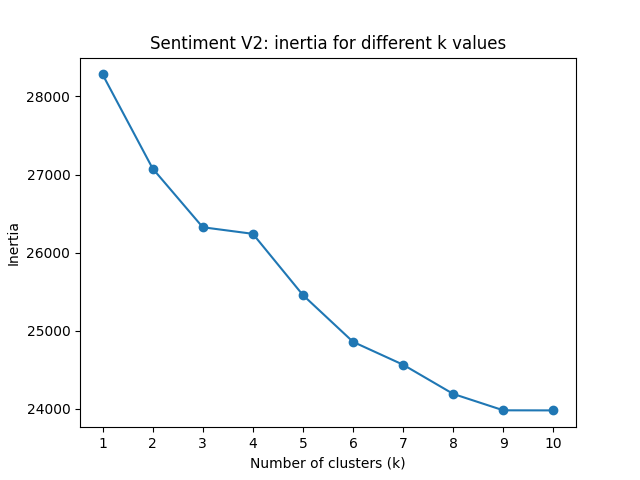

In [4]:
plt.figure()
plt.plot(summary["k"], summary["inertia"], marker="o")
plt.title("Sentiment V2: inertia for different k values")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.savefig(result_dir / "clustering_v2_elbow.png")
plt.show()

inertias = summary["inertia"].tolist()
deltas = [inertias[i] - inertias[i + 1] for i in range(len(inertias) - 1)]
print("Decrease in inertia:")
for k, drop in zip(range(2, 11), deltas):
    print(f"k={k - 1} to k={k}: {drop:.6f}")


I checked that the results for k=3 matched my first experiment.

In [5]:
v1_summary = pd.read_csv(result_dir / "clustering_v1_summary.csv").iloc[0]
v1_counts = pd.read_csv(result_dir / "clustering_v1_cluster_counts.csv")
k3_model = models[3]
k3_result = summary.loc[summary["k"] == 3].iloc[0]
assert indices.tolist() == v1_assignments["original_row_index"].tolist()
assert y_subset.tolist() == v1_assignments["true_label"].tolist()
assert k3_model.labels_.tolist() == v1_assignments["cluster"].tolist()
assert k3_model.n_iter_ == v1_summary["iterations"] == 19
assert np.isclose(k3_model.inertia_, v1_summary["inertia"], rtol=1e-12, atol=1e-8)
assert k3_result["purity"] == v1_summary["purity"] == 0.387
assert k3_result["samples"] == v1_summary["samples"] == 1000
assert k3_result["features"] == v1_summary["features"] == 768
assert k3_model.seed == v1_summary["seed"] == 42
assert k3_model.max_iter == v1_summary["max_iter"] == 100
assert k3_model.tol == 1e-4
for row in v1_counts.itertuples():
    true_in_cluster = y_subset[k3_model.labels_ == row.cluster]
    counts = Counter(true_in_cluster)
    assert len(true_in_cluster) == row.total
    assert counts[0] == row.negative
    assert counts[1] == row.neutral
    assert counts[2] == row.positive
print("k=3 matches V1: row indices, true labels, assignments, iterations, inertia, purity and cluster counts.")


k=3 matches V1: row indices, true labels, assignments, iterations, inertia, purity and cluster counts.


Finally, I saved the results so I can compare them with the next experiment.

In [6]:
assert len(summary) == 10
assert summary["k"].tolist() == list(k_values)
summary.to_csv(result_dir / "clustering_v2_summary.csv", index=False)
print(summary.to_string(index=False))
print("Saved the V2 summary and elbow graph in", result_dir)


version   dataset  samples  features  k  seed  max_iter  iterations      inertia  purity  fit_time_seconds
     V2 sentiment     1000       768  1    42       100           2 28282.657585   0.357          0.091067
     V2 sentiment     1000       768  2    42       100          40 27077.324956   0.357          1.725057
     V2 sentiment     1000       768  3    42       100          19 26325.122315   0.387          1.362958
     V2 sentiment     1000       768  4    42       100          15 26240.771021   0.378          1.297454
     V2 sentiment     1000       768  5    42       100          24 25456.168832   0.407          2.584955
     V2 sentiment     1000       768  6    42       100          22 24857.286626   0.426          2.747420
     V2 sentiment     1000       768  7    42       100          18 24564.197425   0.400          2.427274
     V2 sentiment     1000       768  8    42       100          19 24190.341790   0.430          2.710483
     V2 sentiment     1000       768 